# Activity 5 — Text Extraction


Imports, image folder, and Tesseract setup.

In [4]:
import os
import shutil
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pytesseract
from matplotlib.patches import Patch

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.titleweight': 'bold'})

# Works from the activity folder or the project root.
image_dir = next((p for p in (Path.cwd() / 'images', Path.cwd() / 'Activity 05 - Text Extraction' / 'images')
                if p.is_dir()), None)
if image_dir is None:
    raise FileNotFoundError("Could not find an 'images' folder.")
image_paths = sorted(p for p in image_dir.iterdir()
                if p.suffix.lower() in {'.jpg', '.jpeg', '.png'})

# Tesseract: PATH, TESSERACT_CMD, or the default Windows install.
tesseract_cmd = os.environ.get('TESSERACT_CMD') or shutil.which('tesseract')
if not tesseract_cmd:
    windows_path = Path(os.environ.get('ProgramFiles', 'C:/Program Files')) / 'Tesseract-OCR' / 'tesseract.exe'
    tesseract_cmd = str(windows_path) if windows_path.is_file() else None
if not tesseract_cmd:
    raise RuntimeError('Install Tesseract OCR, then add it to PATH or set TESSERACT_CMD.')
pytesseract.pytesseract.tesseract_cmd = tesseract_cmd

print(f'Tesseract {pytesseract.get_tesseract_version()} · {len(image_paths)} images found')

Tesseract 5.5.3.20260724 · 5 images found


Find the characters: crop, Otsu threshold, then keep tall, narrow contours (skips border, holes, QR code).

In [5]:
def find_characters(image):
    """Return the cropped plate, its binary mask, and the sorted character boxes."""
    height, width = image.shape[:2]
    crop = image[int(height * 0.12):int(height * 0.90), int(width * 0.025):int(width * 0.975)]

    gray = cv2.GaussianBlur(cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY), (3, 3), 0)
    _, binary = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    if cv2.countNonZero(binary) < binary.size / 2:   # make the background white
        binary = cv2.bitwise_not(binary)

    contours, _ = cv2.findContours(255 - binary, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
    boxes = []
    for contour in contours:
        x, y, w, h = cv2.boundingRect(contour)
        if height * 0.26 <= h <= height * 0.78 and width * 0.012 <= w <= width * 0.18 and w < h:
            boxes.append((x, y, w, h))
    return crop, binary, sorted(boxes)

Classify the plate: yellow background means public utility, otherwise the character color decides.

In [6]:
CATEGORIES = {
    'Government':     '#d62828',
    'E-Vehicle':      '#2a9d3f',
    'Public Utility': '#f4c20d',
    'Diplomatic':     '#1d4fb8',
    'Private':        '#222222',
}

def classify_plate(crop, binary, boxes):
    """Return (category, background color name, character color name) from pixel colors."""
    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)

    char_mask = np.zeros(binary.shape, np.uint8)
    for x, y, w, h in boxes:
        char_mask[y:y + h, x:x + w] = 255
    ink = hsv[(char_mask == 255) & (binary == 0)]      # character pixels
    paper = hsv[binary == 255]                         # plate background pixels
    (bg_h, bg_s, _), (ink_h, ink_s, ink_v) = np.median(paper, 0), np.median(ink, 0)

    if 15 <= bg_h <= 35 and bg_s > 100:
        return 'Public Utility', 'yellow', 'black'
    if ink_v < 70 or ink_s < 60:
        ink_name = 'black'
    elif ink_h < 10 or ink_h > 170:
        ink_name = 'red'
    elif 35 <= ink_h <= 85:
        ink_name = 'green'
    elif 95 <= ink_h <= 130:
        ink_name = 'blue'
    else:
        ink_name = 'unknown'
    category = {'red': 'Government', 'green': 'E-Vehicle',
                'blue': 'Diplomatic', 'black': 'Private'}.get(ink_name, 'Unknown')
    return category, 'white', ink_name

Read the text: OCR each character several ways, take the majority vote, then group letters and digits at the widest gap.

In [7]:
from collections import Counter

LETTERS = 'ABCDEFGHIJKLMNOPQRSTUVWXYZ'
DIGITS = '0123456789'

def read_character(binary, box, whitelist):
    """Vote across page modes, padding, and sizes to stabilize one character."""
    x, y, w, h = box
    glyph = binary[y:y + h, x:x + w]
    votes = Counter()
    for size in (100, 140):
        resized = cv2.resize(glyph, None, fx=size / h, fy=size / h, interpolation=cv2.INTER_AREA)
        for pad in (20, 35, 50):
            padded = cv2.copyMakeBorder(resized, pad, pad, pad, pad, cv2.BORDER_CONSTANT, value=255)
            _, padded = cv2.threshold(padded, 127, 255, cv2.THRESH_BINARY)
            for psm in (8, 10, 13):
                config = f'--psm {psm} -c tessedit_char_whitelist={whitelist}'
                text = pytesseract.image_to_string(padded, config=config).strip().upper()
                if text and text[0] in whitelist:
                    votes[text[0]] += 1
    return votes.most_common(1)[0][0] if votes else '?'

def read_plate(binary, boxes):
    """Letters come before the widest gap, digits after it."""
    gaps = [boxes[i + 1][0] - (boxes[i][0] + boxes[i][2]) for i in range(len(boxes) - 1)]
    split = int(np.argmax(gaps)) + 1
    letters = ''.join(read_character(binary, b, LETTERS) for b in boxes[:split])
    digits = ''.join(read_character(binary, b, DIGITS) for b in boxes[split:])
    return f'{letters} {digits}'

def character_strip(binary, boxes):
    """Selected characters only, on white paper, for display."""
    clean = np.full_like(binary, 255)
    for x, y, w, h in boxes:
        clean[y:y + h, x:x + w] = binary[y:y + h, x:x + w]
    left, right = min(b[0] for b in boxes), max(b[0] + b[2] for b in boxes)
    top, bottom = min(b[1] for b in boxes), max(b[1] + b[3] for b in boxes)
    return cv2.copyMakeBorder(clean[top:bottom, left:right], 20, 20, 20, 20, cv2.BORDER_CONSTANT, value=255)

def recognize_plate(path):
    image = cv2.imread(str(path))
    crop, binary, boxes = find_characters(image)
    if not boxes:
        return {'file': path.name, 'plate': '[none]', 'category': 'Unknown', 'background': '-',
                'characters': '-', 'image': image, 'crop': crop, 'boxes': [], 'ocr_input': binary}
    category, background, ink = classify_plate(crop, binary, boxes)
    return {'file': path.name, 'plate': read_plate(binary, boxes), 'category': category,
            'background': background, 'characters': ink, 'image': image, 'crop': crop,
            'boxes': boxes, 'ocr_input': character_strip(binary, boxes)}

Run on every image and show each processing stage.

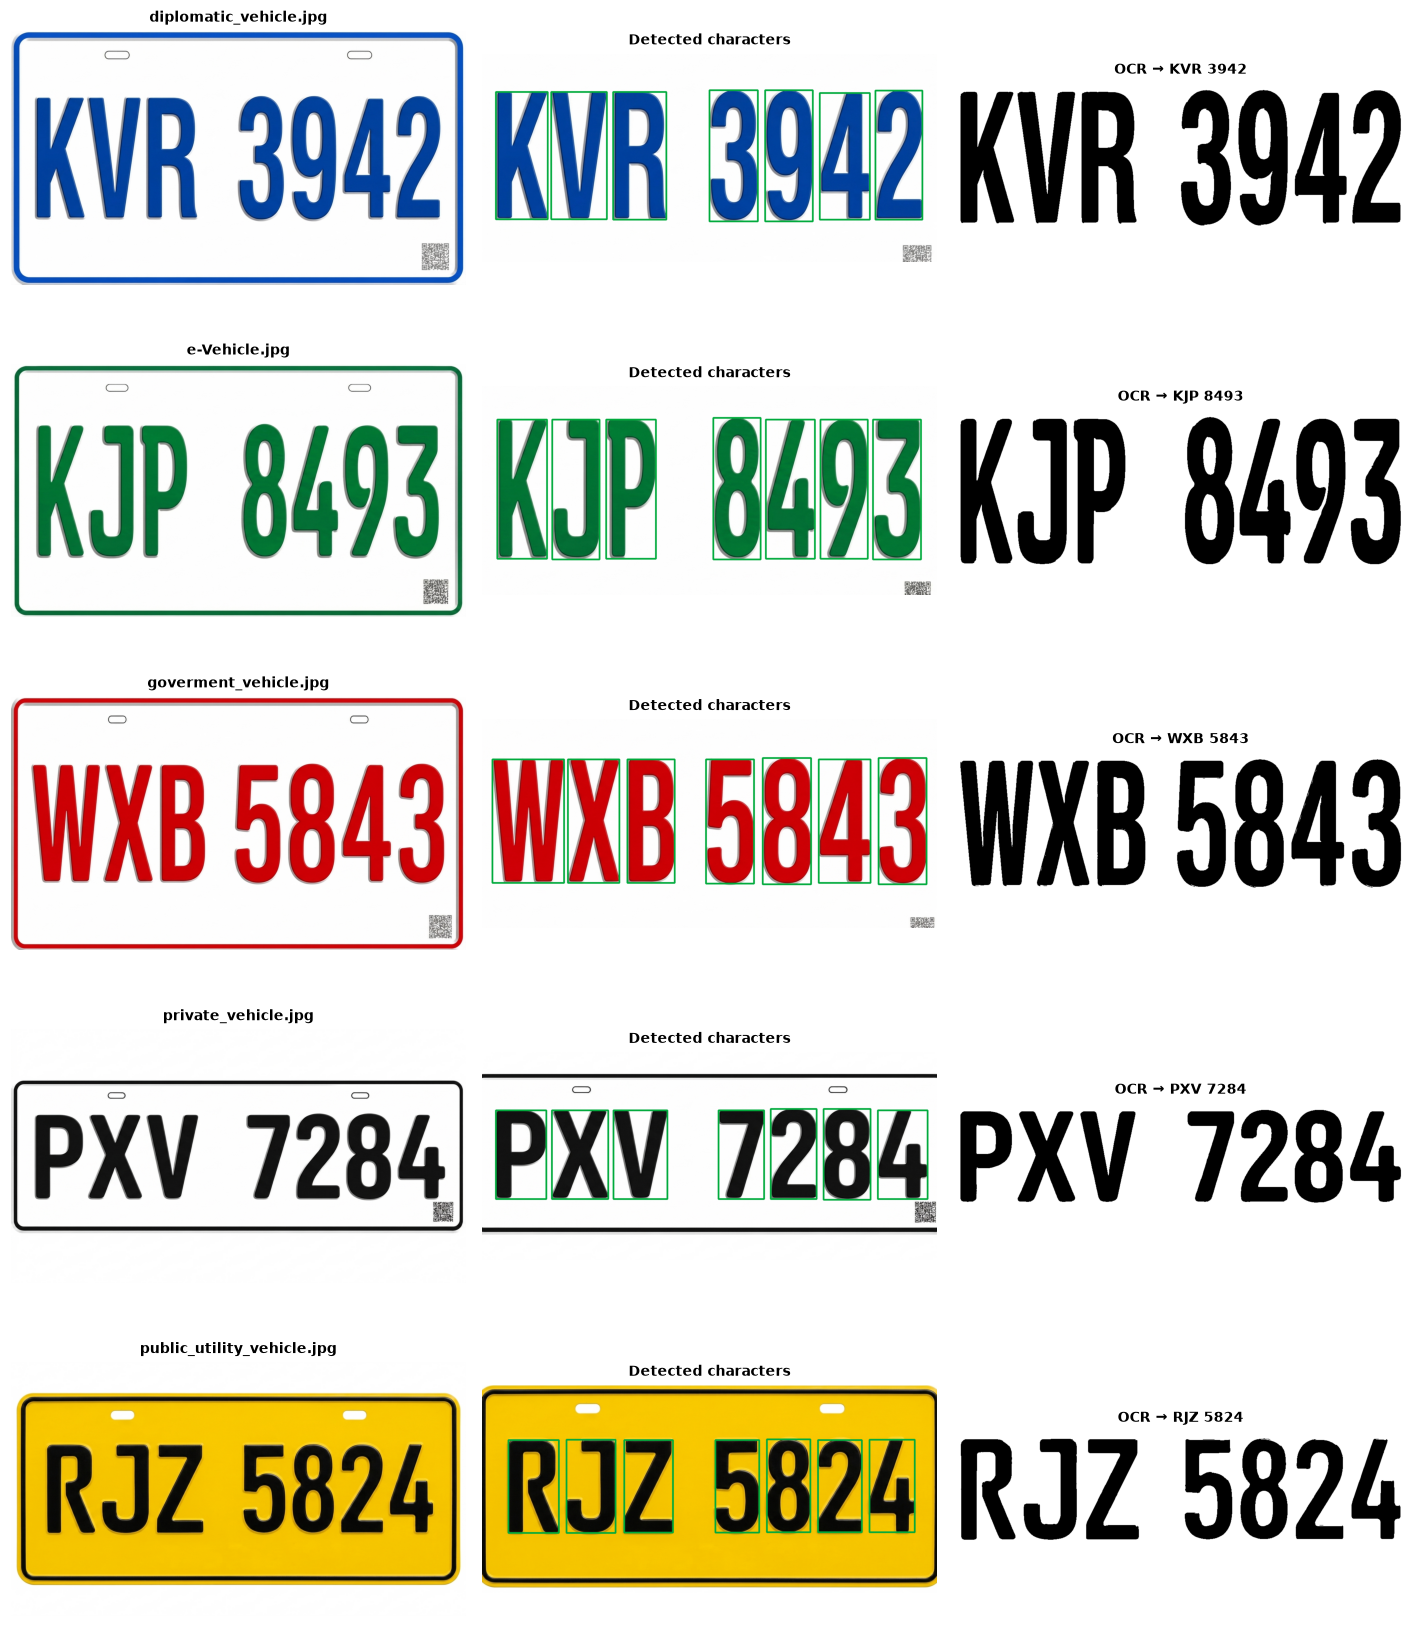

In [8]:
results = [recognize_plate(p) for p in image_paths]

fig, axes = plt.subplots(len(results), 3, figsize=(13, 3.1 * len(results)), squeeze=False)
for row, r in zip(axes, results):
    annotated = cv2.cvtColor(r['crop'], cv2.COLOR_BGR2RGB)
    for x, y, w, h in r['boxes']:
        cv2.rectangle(annotated, (x, y), (x + w, y + h), (0, 170, 60), 4)

    row[0].imshow(cv2.cvtColor(r['image'], cv2.COLOR_BGR2RGB)); row[0].set_title(r['file'], fontsize=9)
    row[1].imshow(annotated);                                  row[1].set_title('Detected characters', fontsize=9)
    row[2].imshow(r['ocr_input'], cmap='gray');                row[2].set_title(f"OCR → {r['plate']}", fontsize=9)
    for ax in row:
        ax.axis('off')
plt.tight_layout()
plt.show()

Final results.

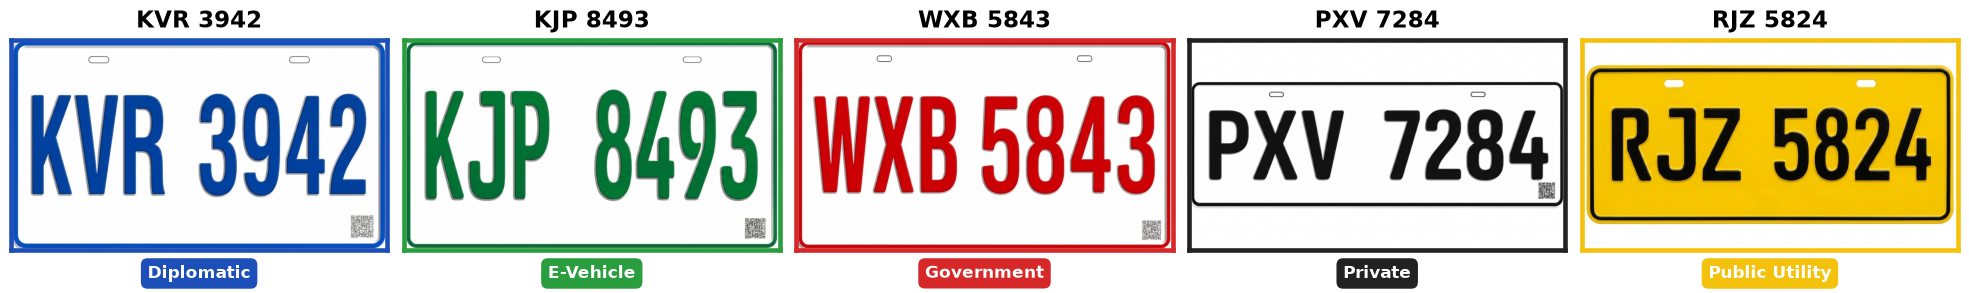

File,Plate number,Vehicle type,Background,Characters
diplomatic_vehicle.jpg,KVR 3942,Diplomatic,white,blue
e-Vehicle.jpg,KJP 8493,E-Vehicle,white,green
goverment_vehicle.jpg,WXB 5843,Government,white,red
private_vehicle.jpg,PXV 7284,Private,white,black
public_utility_vehicle.jpg,RJZ 5824,Public Utility,yellow,black


In [9]:
fig, axes = plt.subplots(1, len(results), figsize=(3.6 * len(results), 3.1))
for ax, r in zip(np.atleast_1d(axes), results):
    color = CATEGORIES.get(r['category'], '#888888')
    ax.imshow(cv2.cvtColor(r['image'], cv2.COLOR_BGR2RGB))
    ax.set_title(r['plate'], fontsize=15, pad=8)
    ax.set_xlabel(r['category'], fontsize=11, fontweight='bold', color='white',
                bbox=dict(boxstyle='round,pad=0.4', fc=color, ec='none'),
                labelpad=10)
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_edgecolor(color); spine.set_linewidth(3)
plt.tight_layout()
plt.show()

summary = pd.DataFrame([{'File': r['file'], 'Plate number': r['plate'], 'Vehicle type': r['category'],
                        'Background': r['background'], 'Characters': r['characters']} for r in results])
summary.style.hide(axis='index').set_properties(**{'text-align': 'left'})